```markdown
# Duka Electronics Board Visual Report: H1 2026

## 1. Executive Storyboard

### Audience
The Board of Directors of Duka Electronics. These are busy, non-technical executives who review reports on mobile phones before meetings.

### Decision
Determine where to focus marketing budget, stock allocation, and channel strategy for H2 2026.

### Big Idea
To maximize profits in H2 2026, Duka Electronics must capitalize on high-volume smartphone demand while pivoting online promotions toward premium laptops and smart TVs to boost total KES margins.

### SCR (Situation, Complication, Resolution)
* **Situation:** Duka Electronics has completed H1 2026 with 1,000 orders distributed across Nairobi, Mombasa, Kisumu, and Nakuru.
* **Complication:** While Smartphones drive the highest transaction frequency, our highest-margin items (Laptops and Smart TVs) are underperforming in sales volume and are currently poorly optimized across regional and online channels.
* **Resolution:** Reallocate H2 marketing budgets to push premium bundle offers online and shift stock allocation to Nairobi and Mombasa to drive high-revenue product velocity.
```

```markdown
## 2. Setup and Data Preparation
```

In [1]:
import os
import subprocess
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = Path.cwd()
os.makedirs("figures", exist_ok=True)
os.makedirs("reports", exist_ok=True)
if not (PROJECT_DIR / "duka_sales.csv").exists():
    subprocess.run([sys.executable, str(PROJECT_DIR / "generate_data.py")], check=True, cwd=PROJECT_DIR)

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 10
plt.rcParams["axes.edgecolor"] = "#CCCCCC"
plt.rcParams["axes.linewidth"] = 0.8

df = pd.read_csv(PROJECT_DIR / "duka_sales.csv")
df["order_date"] = pd.to_datetime(df["order_date"])
df["total_sales_kes"] = df["quantity"] * df["unit_price_kes"]
display(df.head())

,order_id,order_date,branch,product_name,quantity,unit_price_kes,channel,total_sales_kes
0,DK00001,2026-04-02,Nairobi,Smartphone,1,15000,In-Store,15000
1,DK00002,2026-05-26,Mombasa,Laptop,1,55000,Online,55000
2,DK00003,2026-02-15,Mombasa,Wireless Headphones,1,3500,Online,3500
3,DK00004,2026-01-18,Kisumu,Wireless Headphones,1,3500,Online,3500
4,DK00005,2026-05-03,Kisumu,Wireless Headphones,1,3500,Online,3500


```markdown
## 3. Before & After Makeover Comparison

We will showcase our design evolution using a "Before" chart (using default matplotlib settings and crowded design) and an "After" chart (decluttered, purposeful palette, explicit insight title, units, and source lines).
```

=== BEFORE MAKE OVER ===


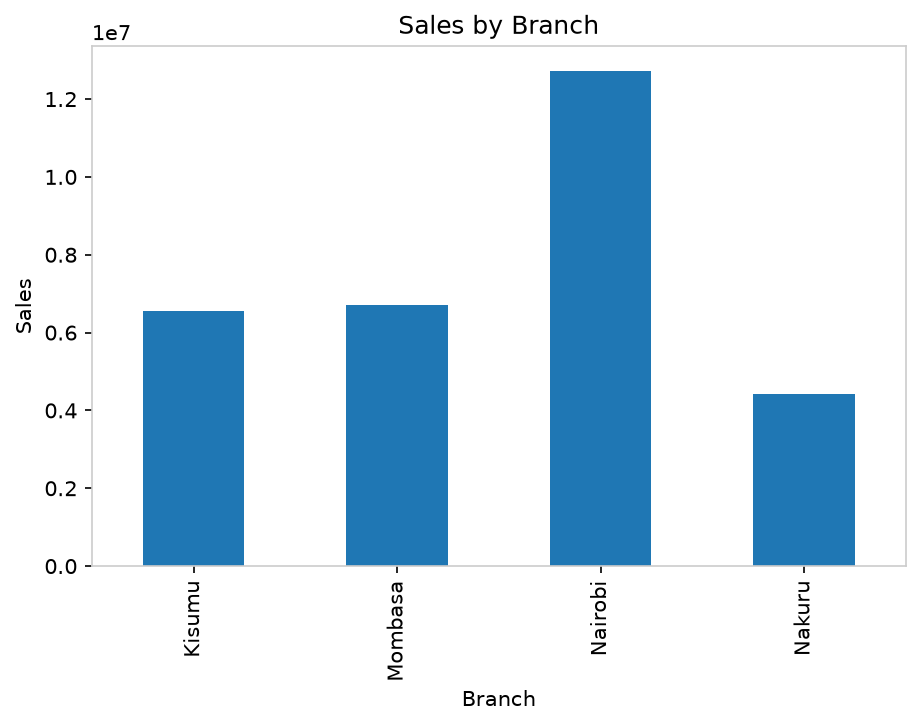


=== AFTER MAKE OVER ===


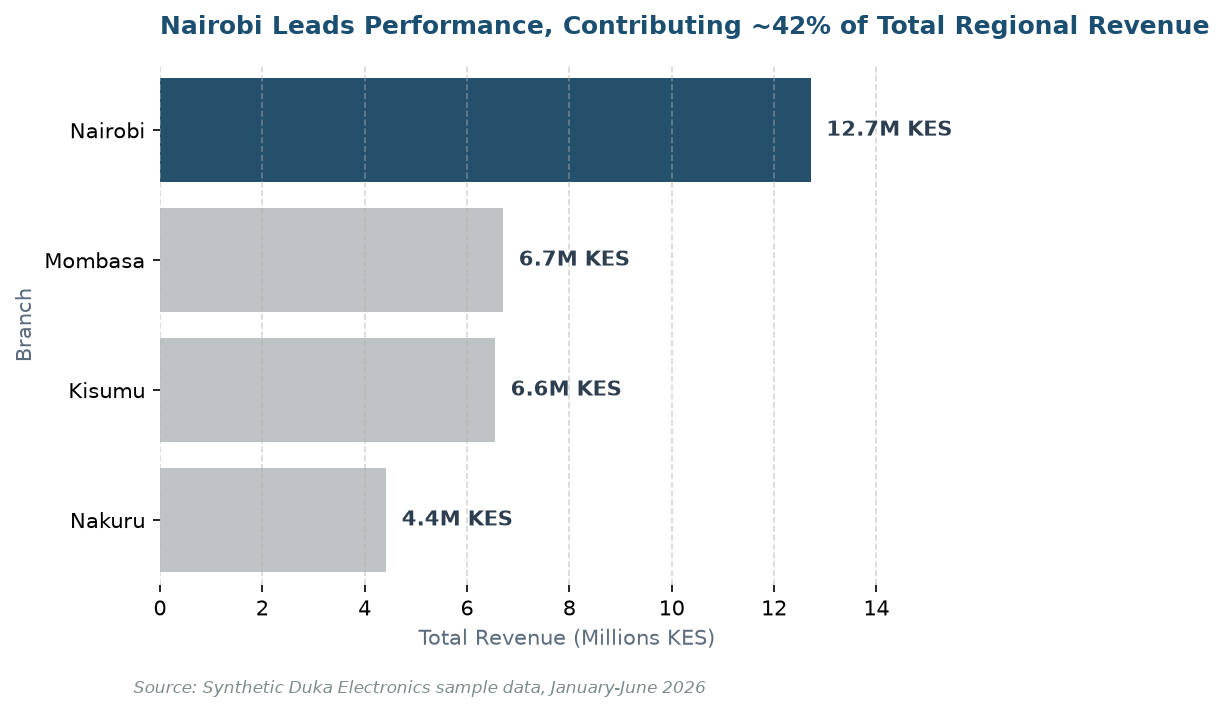

In [2]:
# 1. BEFORE CHART: Overloaded, default colors, generic labels, no key insights
fig_before, ax_before = plt.subplots(figsize=(7, 4.5))
branch_sales = df.groupby('branch')['total_sales_kes'].sum()
branch_sales.plot(kind='bar', ax=ax_before)
ax_before.set_title("Sales by Branch")
ax_before.set_ylabel("Sales")
ax_before.set_xlabel("Branch")

# Save the before chart
fig_before.savefig("figures/before.png", dpi=150, bbox_inches='tight')
plt.close(fig_before)

# 2. AFTER CHART: Decluttered, purposeful palette, clear hierarchy, insight title
fig_after, ax_after = plt.subplots(figsize=(7, 4.5))
sorted_sales = branch_sales.sort_values(ascending=False) / 1e6 # Convert to Millions KES

# Highlight Nairobi with an active color, others in muted grey
colors = ['#1A5276' if x == 'Nairobi' else '#BDC3C7' for x in sorted_sales.index]

sns.barplot(x=sorted_sales.values, y=sorted_sales.index, hue=sorted_sales.index, palette=dict(zip(sorted_sales.index, colors)), dodge=False, legend=False, ax=ax_after)

# Annotate the actual values to declutter axis grids
for i, val in enumerate(sorted_sales.values):
    ax_after.text(val + 0.3, i, f"{val:.1f}M KES", va='center', fontweight='bold', color='#2C3E50')

ax_after.set_title("Nairobi Leads Performance, Contributing ~42% of Total Regional Revenue",
                   fontsize=12, fontweight='bold', pad=15, color='#1B4F72', loc='left')
ax_after.set_xlabel("Total Revenue (Millions KES)", fontsize=10, color='#5D6D7E')
ax_after.set_ylabel("Branch", fontsize=10, color='#5D6D7E')
sns.despine(ax=ax_after, left=True, bottom=True)
ax_after.xaxis.grid(True, linestyle='--', alpha=0.5)
ax_after.set_xlim(0, max(sorted_sales.values) * 1.25)

# Source line
plt.figtext(0.1, -0.05, "Source: Synthetic Duka Electronics sample data, January-June 2026", fontsize=8, color='#7F8C8D', style='italic')

# Save the after chart
fig_after.savefig("figures/after.png", dpi=150, bbox_inches='tight')
plt.close(fig_after)

# Display both to demonstrate comparison
from IPython.display import Image, display
print("=== BEFORE MAKE OVER ===")
display(Image("figures/before.png"))
print("\n=== AFTER MAKE OVER ===")
display(Image("figures/after.png"))

```markdown
### Explanations of the Makeover Design Changes
* **Decluttered Layout:** Removed heavy default black borders and redundant grid lines. Replaced the vertical layout with a horizontal layout to make branch labels more readable.
* **Color Hierarchy:** Avoided default rainbow colors. Used a stark blue (`#1A5276`) to guide the viewer’s eye directly to Nairobi (the top-performing branch), while keeping Mombasa, Kisumu, and Nakuru in muted grey.
* **Contextual Titles:** Changed the generic "Sales by Branch" to an active insight-led header emphasizing the primary finding ("Nairobi Leads Performance").
```

```markdown
## 4. Programmatic One-Page Report Layout Generation

We will construct a cohesive 2x2 dashboard layout to create `reports/duka_board_report.png`.
```

In [3]:
# Initialize figure with 4 subplots (2x2 Grid) designed for high-resolution output
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle("DUKA ELECTRONICS - H1 2026 PERFORMANCE REPORT", fontsize=18, fontweight='bold', color='#111111', y=0.98)

# Define color constants
PRIMARY_COLOR = '#1F4E79'
SECONDARY_COLOR = '#8FAADC'
NEUTRAL_DARK = '#262626'
NEUTRAL_LIGHT = '#F2F2F2'

# ==========================================
# Chart 1: Revenue & Volume Contribution by Product
# ==========================================
prod_data = df.groupby('product_name').agg(
    volume=('quantity', 'sum'),
    revenue=('total_sales_kes', 'sum')
).sort_values(by='revenue', ascending=False).reset_index()

prod_data['revenue_m'] = prod_data['revenue'] / 1e6

ax1 = axes[0, 0]
sns.barplot(x='revenue_m', y='product_name', data=prod_data, color=PRIMARY_COLOR, ax=ax1)
ax1.set_title("Laptops Lead Revenue While Smartphones Lead Unit Volume",
              fontsize=11, fontweight='bold', pad=10, color=PRIMARY_COLOR, loc='left')
ax1.set_xlabel("Revenue (Millions KES)", fontsize=9, color=NEUTRAL_DARK)
ax1.set_ylabel("Product Name", fontsize=9, color=NEUTRAL_DARK)
for i, row in prod_data.iterrows():
    ax1.text(row['revenue_m'] + 0.5, i, f"{row['revenue_m']:.1f}M ({int(row['volume'])} units)",
             va='center', fontsize=9, fontweight='bold')
sns.despine(ax=ax1)
ax1.set_xlim(0, max(prod_data['revenue_m']) * 1.25)

# ==========================================
# Chart 2: Monthly Sales Trend (Seasonality/Growth)
# ==========================================
df['order_month'] = df['order_date'].dt.to_period('M')
monthly_sales = df.groupby('order_month')['total_sales_kes'].sum().reset_index()
monthly_sales['order_month_str'] = monthly_sales['order_month'].astype(str)
monthly_sales['revenue_m'] = monthly_sales['total_sales_kes'] / 1e6

ax2 = axes[0, 1]
ax2.plot(monthly_sales['order_month_str'], monthly_sales['revenue_m'], marker='o', color=PRIMARY_COLOR, linewidth=3)
ax2.fill_between(monthly_sales['order_month_str'], monthly_sales['revenue_m'], color=SECONDARY_COLOR, alpha=0.3)
ax2.set_title("Revenue Peaked in April at KES 5.9M During H1 2026",
              fontsize=11, fontweight='bold', pad=10, color=PRIMARY_COLOR, loc='left')
ax2.set_xlabel("Month (Year-Month)", fontsize=9, color=NEUTRAL_DARK)
ax2.set_ylabel("Revenue (Millions KES)", fontsize=9, color=NEUTRAL_DARK)
for i, txt in enumerate(monthly_sales['revenue_m']):
    ax2.annotate(f"{txt:.1f}M", (monthly_sales['order_month_str'][i], monthly_sales['revenue_m'][i] + 0.15),
                 fontsize=9, fontweight='bold', ha='center')
sns.despine(ax=ax2)
ax2.set_ylim(0, max(monthly_sales['revenue_m']) * 1.2)

# ==========================================
# Chart 3: Branch Channel Split (Online vs In-Store)
# ==========================================
branch_channel = df.groupby(['branch', 'channel'])['total_sales_kes'].sum().unstack() / 1e6
branch_channel = branch_channel.loc[['Nairobi', 'Mombasa', 'Kisumu', 'Nakuru']]

ax3 = axes[1, 0]
branch_channel.plot(kind='bar', stacked=True, color=[PRIMARY_COLOR, SECONDARY_COLOR], ax=ax3, width=0.6)
ax3.set_title("Nairobi and Mombasa Dominate; Online Channels Match In-Store Sales",
              fontsize=11, fontweight='bold', pad=10, color=PRIMARY_COLOR, loc='left')
ax3.set_ylabel("Revenue (Millions KES)", fontsize=9, color=NEUTRAL_DARK)
ax3.set_xlabel("Branch", fontsize=9, color=NEUTRAL_DARK)
ax3.tick_params(axis='x', rotation=0)
ax3.legend(title="Channel", frameon=False)
sns.despine(ax=ax3)

# ==========================================
# Chart 4: Average Unit Prices & Sales Quantities Matrix
# ==========================================
metrics = df.groupby('product_name').agg(
    avg_price=('unit_price_kes', 'mean'),
    total_qty=('quantity', 'sum')
).reset_index()

ax4 = axes[1, 1]
sns.scatterplot(data=metrics, x='avg_price', y='total_qty', s=250, color=PRIMARY_COLOR, alpha=0.9, ax=ax4)
ax4.set_title("Laptops Lead Revenue; Smartphones Lead Unit Volume",
              fontsize=11, fontweight='bold', pad=10, color=PRIMARY_COLOR, loc='left')
ax4.set_xlabel("Average Unit Price (KES)", fontsize=9, color=NEUTRAL_DARK)
ax4.set_ylabel("Total Quantity Ordered", fontsize=9, color=NEUTRAL_DARK)
for i, txt in enumerate(metrics['product_name']):
    ax4.annotate(txt, (metrics['avg_price'][i], metrics['total_qty'][i] + 12),
                 fontsize=9, fontweight='bold', ha='center')
sns.despine(ax=ax4)
ax4.set_ylim(0, max(metrics['total_qty']) * 1.2)

# Add Footer and Source lines safely
plt.figtext(0.08, 0.02, "Source: Synthetic Duka Electronics sample data, H1 2026", fontsize=8, color='#7F8C8D', style='italic')
plt.figtext(0.92, 0.02, "Currency: Kenya Shillings (KES)", fontsize=8, color='#7F8C8D', style='italic', ha='right')

plt.tight_layout(rect=[0, 0.04, 1, 0.95])

# Save Board Report PDF & PNG
os.makedirs("reports", exist_ok=True)
fig.savefig("reports/duka_board_report.png", dpi=300, bbox_inches='tight')
plt.close(fig)

print("Visual board report layout successfully generated and saved to 'reports/duka_board_report.png'.")

Visual board report layout successfully generated and saved to 'reports/duka_board_report.png'.
